In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file = '/content/drive/MyDrive/Tumor_Dataset.zip'

In [ ]:
import zipfile as zf
data_zip = zf.ZipFile(file)
data_zip.extractall()
!ls

drive  sample_data  Tumor_Dataset


In [ ]:
from pathlib import Path
data = Path(r'/content/Tumor_Dataset')

In [ ]:
#list of useful libraries required for the project
import os
import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import cv2
from glob import glob
import seaborn as sns
import random
from keras.preprocessing import image
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense,Dropout,Flatten,Conv2D,MaxPool2D,GlobalAvgPool2D,GlobalMaxPooling2D
from keras.optimizers import RMSprop
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.optimizers import Adam
from sklearn.model_selection import train_test_split

In [ ]:
images=[]
import os
for dirname,_,filenames in os.walk(data):
  for filename in filenames:
    file_name, file_extension = os.path.splitext(filename)
    if file_extension == '.db':
      continue
    else:
      img=os.path.join(dirname,filename)
      images.append(img)

In [ ]:
images[:20]

['/content/Tumor_Dataset/meningioma_tumor/m3 (20).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m2 (122).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m2 (113).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m (82).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m3 (216).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m (78).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m3 (59).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m1(71).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m2 (133).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m (139).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m1(86).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m1(75).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m (147).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m3 (175).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m3 (118).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m3 (176).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m (28).jpg',
 '/content/Tumor_Dataset/meningioma_tumor/m1(10

In [ ]:
len(images)

2870

In [ ]:
class_values = []
for i in images:
    j = i.split('/')
    class_values.append(j[-2])

In [ ]:
class_values[:10]

['meningioma_tumor',
 'meningioma_tumor',
 'meningioma_tumor',
 'meningioma_tumor',
 'meningioma_tumor',
 'meningioma_tumor',
 'meningioma_tumor',
 'meningioma_tumor',
 'meningioma_tumor',
 'meningioma_tumor']

In [ ]:
len(class_values)

2870

In [ ]:
import random # Import the random module at the beginning of the cell
temp = list(zip(images,class_values))
random.shuffle(temp)
images, class_values = zip(*temp)
data = pd.DataFrame(list(zip(images, class_values)), columns=['image_path', 'Class_label'])

In [ ]:
data

,image_path,Class_label
0,/content/Tumor_Dataset/pituitary_tumor/p (757)...,pituitary_tumor
1,/content/Tumor_Dataset/meningioma_tumor/m (97)...,meningioma_tumor
2,/content/Tumor_Dataset/meningioma_tumor/m2 (59...,meningioma_tumor
3,/content/Tumor_Dataset/meningioma_tumor/m1(121...,meningioma_tumor
4,/content/Tumor_Dataset/no_tumor/image (21).jpg,no_tumor
...,...,...
2865,/content/Tumor_Dataset/meningioma_tumor/m (38)...,meningioma_tumor
2866,/content/Tumor_Dataset/glioma_tumor/gg (555).jpg,glioma_tumor
2867,/content/Tumor_Dataset/meningioma_tumor/m1(8).jpg,meningioma_tumor
2868,/content/Tumor_Dataset/no_tumor/image(81).jpg,no_tumor


In [ ]:
data.shape

(2870, 2)

In [ ]:
data.Class_label.value_counts()

,count
Class_label,
pituitary_tumor,827
glioma_tumor,826
meningioma_tumor,822
no_tumor,395


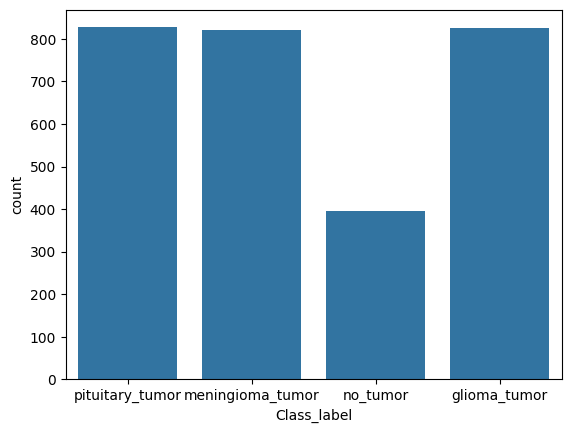

In [ ]:
sns.countplot(x = data.Class_label, data = data)
plt.show()

In [ ]:
from sklearn.utils import resample

# The original filter was using integers (1 and 0) but the 'Class_label' column seems to contain strings
# Correcting the filter condition to use strings ('1' and '0') should fix the issue
df_c0 = data[data['Class_label'] == 'pituitary_tumor']
df_c1 = data[data['Class_label'] == 'glioma_tumor']
df_c2 = data[data['Class_label'] == 'meningioma_tumor']
df_c3 = data[data['Class_label'] == 'no_tumor']


unsampled_df_c0 = resample(df_c0, replace=True, random_state=23, n_samples=2000)
unsampled_df_c1 = resample(df_c1, replace=True, random_state=23, n_samples=2000)
unsampled_df_c2 = resample(df_c2, replace=True, random_state=23, n_samples=2000)
unsampled_df_c3 = resample(df_c3, replace=True, random_state=23, n_samples=2000)

df_unsampled = pd.concat([unsampled_df_c0, unsampled_df_c1, unsampled_df_c2, unsampled_df_c3])
df_unsampled

,image_path,Class_label
2044,/content/Tumor_Dataset/pituitary_tumor/p (12).jpg,pituitary_tumor
2581,/content/Tumor_Dataset/pituitary_tumor/p (39).jpg,pituitary_tumor
154,/content/Tumor_Dataset/pituitary_tumor/p (577)...,pituitary_tumor
1675,/content/Tumor_Dataset/pituitary_tumor/p (279)...,pituitary_tumor
128,/content/Tumor_Dataset/pituitary_tumor/p (609)...,pituitary_tumor
...,...,...
2670,/content/Tumor_Dataset/no_tumor/image(248).jpg,no_tumor
767,/content/Tumor_Dataset/no_tumor/image(214).jpg,no_tumor
2169,/content/Tumor_Dataset/no_tumor/image(65).jpg,no_tumor
2677,/content/Tumor_Dataset/no_tumor/image(144).jpg,no_tumor


In [ ]:
df_unsampled.Class_label.value_counts()

,count
Class_label,
pituitary_tumor,2000
glioma_tumor,2000
meningioma_tumor,2000
no_tumor,2000


In [ ]:
data = df_unsampled.sample(frac=1)
data.shape

(8000, 2)

In [ ]:
df = data

In [ ]:
import os
from PIL import Image

In [ ]:
def resize_images(img):
  file = Image.open(img)
  img = file.convert('RGB')
  img_bgr= img.resize((124, 124))
  img_bgr = np.array(img_bgr)
  return img_bgr

In [ ]:
#save resized images into images.
images = [resize_images(img) for img in df['image_path']]

In [ ]:
images

[array([[[ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0],
         ...,
         [ 1,  1,  1],
         [ 1,  1,  1],
         [ 1,  1,  1]],
 
        [[ 3,  3,  3],
         [ 5,  5,  5],
         [ 5,  5,  5],
         ...,
         [ 5,  5,  5],
         [ 4,  4,  4],
         [ 4,  4,  4]],
 
        [[ 6,  6,  6],
         [ 9,  9,  9],
         [10, 10, 10],
         ...,
         [10, 10, 10],
         [ 9,  9,  9],
         [ 8,  8,  8]],
 
        ...,
 
        [[ 6,  6,  6],
         [ 7,  7,  7],
         [ 8,  8,  8],
         ...,
         [ 8,  8,  8],
         [ 7,  7,  7],
         [ 7,  7,  7]],
 
        [[ 2,  2,  2],
         [ 3,  3,  3],
         [ 2,  2,  2],
         ...,
         [ 4,  4,  4],
         [ 4,  4,  4],
         [ 4,  4,  4]],
 
        [[ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0],
         ...,
         [ 0,  0,  0],
         [ 0,  0,  0],
         [ 0,  0,  0]]], dtype=uint8),
 array([[[ 0,  0,  0],
         [ 0,  0,  

In [ ]:
# print number of classes in our dataset
num_classes = len(np.unique(data['Class_label']))

In [ ]:
num_classes

4

In [ ]:
# save the class into class_names
class_names = list(data['Class_label'])

In [ ]:
# Print the shape of the image
images[25].shape

(124, 124, 3)

Text(0.5, 1.0, 'glioma_tumor')

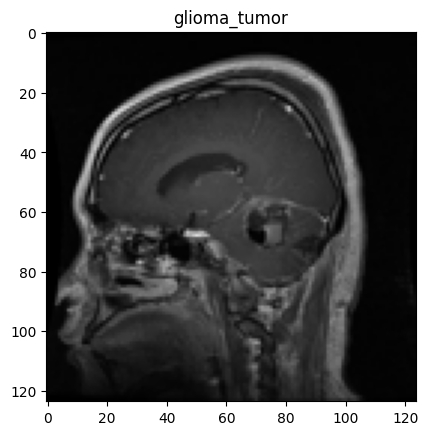

In [ ]:
#See the image with class label
plt.imshow(images[20])
plt.title(class_names[20])

Text(0.5, 1.0, 'meningioma_tumor')

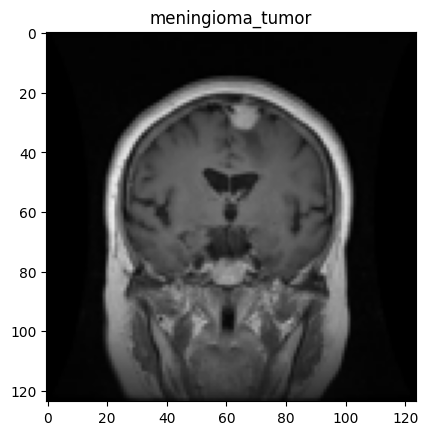

In [ ]:
#See the image with class label
plt.imshow(images[250])
plt.title(class_names[250])

In [ ]:
# Convert the images into array
images =  np.array(images)

In [ ]:
# Shape of the images
images.shape

(8000, 124, 124, 3)

In [ ]:
from sklearn.preprocessing import LabelEncoder
enc=LabelEncoder()
Y = enc.fit_transform(df['Class_label'])
from keras.utils  import to_categorical
y = to_categorical(Y)

In [ ]:
enc.classes_

array(['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor'],
      dtype=object)

In [ ]:
y[:10]

array([[0., 0., 0., 1.],
       [0., 0., 0., 1.],
       [0., 1., 0., 0.],
       [0., 0., 1., 0.],
       [0., 1., 0., 0.],
       [1., 0., 0., 0.],
       [0., 0., 0., 1.],
       [1., 0., 0., 0.],
       [0., 0., 0., 1.],
       [1., 0., 0., 0.]])

In [ ]:
y.shape

(8000, 4)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(images, y, test_size=0.3,stratify = y,random_state=42)

##  CNN Model

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import mixed_precision

# Enable Mixed Precision for Faster Training
mixed_precision.set_global_policy('mixed_float16')

# Image size & Training Parameters
IMG_SIZE = 124
BATCH_SIZE = 64
EPOCHS = 50 # Changed from 20 to 50

# Data Augmentation
train_datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.1,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8, 1.2]
)

# Apply augmentation only to training data
train_generator = train_datagen.flow(X_train, y_train, batch_size=BATCH_SIZE)

# Build CNN Model
model = Sequential([
    Conv2D(64, (3,3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)), # Changed filters from 32 to 64
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'), # Changed filters from 64 to 128
    BatchNormalization(),
    MaxPooling2D(2,2),

    Conv2D(256, (3,3), activation='relu'), # Changed filters from 128 to 256
    BatchNormalization(),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(512, activation='relu'), # Changed neurons from 256 to 512
    BatchNormalization(),
    Dropout(0.3),

    Dense(256, activation='relu'), # Changed neurons from 128 to 256
    BatchNormalization(),
    Dropout(0.3),

    Dense(4, activation='softmax', dtype="float32")  # 4 Classes
])

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True) # Changed patience from 5 to 10
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-7) # Changed patience from 3 to 5 and min_lr from 1e-6 to 1e-7

# Train the model
history = model.fit(
    train_generator,
    validation_data=(X_test, y_test),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 68s 470ms/step - accuracy: 0.5206 - loss: 1.4022 - val_accuracy: 0.4304 - val_loss: 1.5723 - learning_rate: 1.0000e-04
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 23s 265ms/step - accuracy: 0.6637 - loss: 0.8967 - val_accuracy: 0.6796 - val_loss: 0.8465 - learning_rate: 1.0000e-04
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 269ms/step - accuracy: 0.7152 - loss: 0.7348 - val_accuracy: 0.7883 - val_loss: 0.5853 - learning_rate: 1.0000e-04
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 275ms/step - accuracy: 0.7625 - loss: 0.6312 - val_accuracy: 0.8000 - val_loss: 0.5481 - learning_rate: 1.0000e-04
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 276ms/step - accuracy: 0.7988 - loss: 0.5583 - val_accuracy: 0.8229 - val_loss: 0.4819 - learning_rate: 1.0000e-04
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 25s 285ms/step - accuracy: 0.8288 - loss: 0.4478 - val_accuracy: 0.8033 - val_loss: 0.5236 - learning_rate: 1.0000e-04
Epoch 7/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 277ms/step - acc

In [ ]:
# Evaluate the trained model
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=1)
print(f"Test Accuracy: {test_acc * 100:.2f}%")


75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9654 - loss: 0.1140
Test Accuracy: 96.29%


In [ ]:
# Save the trained CNN model
model.save("brain_tumor_cnn.h5")
print("Model saved successfully as brain_tumor_cnn.h5")


Model saved successfully as brain_tumor_cnn.h5


In [ ]:
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score
import numpy as np

# Predictions
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Metrics
precision = precision_score(y_true_classes, y_pred_classes, average='weighted')
recall = recall_score(y_true_classes, y_pred_classes, average='weighted')
f1 = f1_score(y_true_classes, y_pred_classes, average='weighted')

print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(y_true_classes, y_pred_classes))


75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Precision : 0.9641
Recall    : 0.9629
F1-Score  : 0.9627

Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.96      0.97       600
           1       0.98      0.90      0.94       600
           2       0.98      1.00      0.99       600
           3       0.92      0.99      0.96       600

    accuracy                           0.96      2400
   macro avg       0.96      0.96      0.96      2400
weighted avg       0.96      0.96      0.96      2400



75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Classification Report - CNN

              precision    recall  f1-score   support

      Glioma       0.98      0.96      0.97       600
  Meningioma       0.98      0.90      0.94       600
   Pituitary       0.98      1.00      0.99       600
    No Tumor       0.92      0.99      0.96       600

    accuracy                           0.96      2400
   macro avg       0.96      0.96      0.96      2400
weighted avg       0.96      0.96      0.96      2400



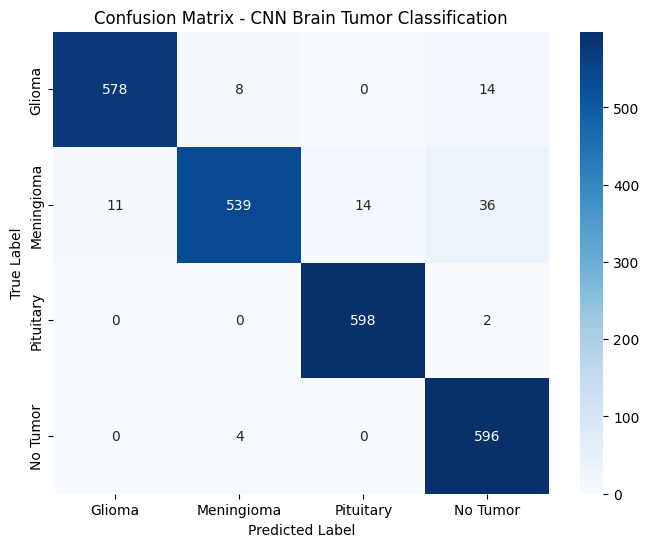

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# =========================
# Class Names (EDIT IF NEEDED)
# =========================
class_names = [
    "Glioma",
    "Meningioma",
    "Pituitary",
    "No Tumor"
]

# =========================
# Predictions
# =========================
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)   # Predicted labels
y_true_classes = np.argmax(y_test, axis=1)   # True labels

# =========================
# Classification Report
# =========================
print("Classification Report - CNN\n")
print(classification_report(
    y_true_classes,
    y_pred_classes,
    target_names=class_names
))

# =========================
# Confusion Matrix
# =========================
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - CNN Brain Tumor Classification")
plt.show()


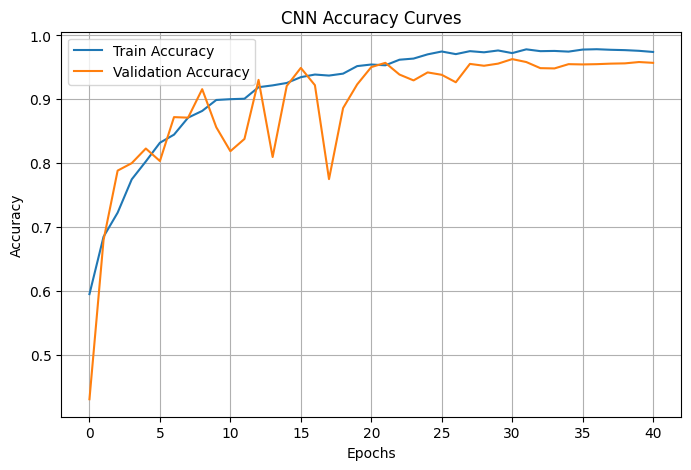

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy Curves")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


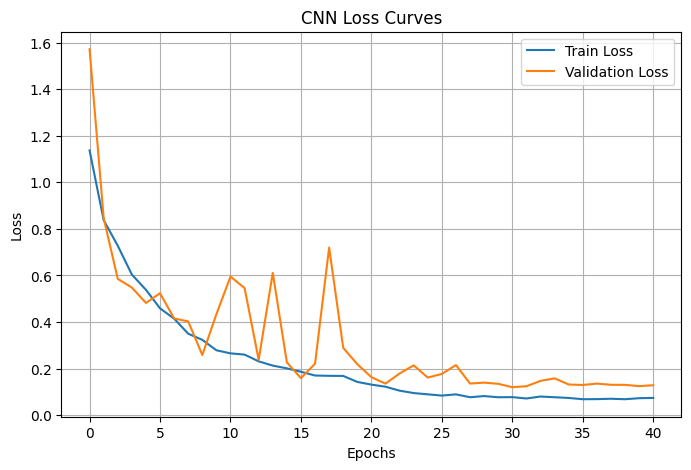

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss Curves")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


# Resnet Model

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import mixed_precision

# ================================
# Enable Mixed Precision
# ================================
mixed_precision.set_global_policy('mixed_float16')

# ================================
# Image size & Training Parameters
# ================================
IMG_SIZE = 124
BATCH_SIZE = 64
EPOCHS = 50

# ================================
# Data Augmentation
# ================================
train_datagen = ImageDataGenerator(
    rotation_range=20,
    zoom_range=0.1,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8, 1.2]
)

train_generator = train_datagen.flow(
    X_train,
    y_train,
    batch_size=BATCH_SIZE
)

# ================================
# Load ResNet50 (without top)
# ================================
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze base model
base_model.trainable = False

# ================================
# Custom Classification Head
# ================================
x = GlobalAveragePooling2D()(base_model.output)

x = Dense(512, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

output = Dense(4, activation='softmax', dtype='float32')(x)

# ================================
# Build Model
# ================================
model = Model(inputs=base_model.input, outputs=output)

# ================================
# Compile
# ================================
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# ================================
# Callbacks
# ================================
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=1e-7
)

# ================================
# Train
# ================================
history = model.fit(
    train_generator,
    validation_data=(X_test, y_test),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 57s 459ms/step - accuracy: 0.4732 - loss: 1.4338 - val_accuracy: 0.7150 - val_loss: 0.7053 - learning_rate: 1.0000e-04
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 275ms/step - accuracy: 0.7257 - loss: 0.7205 - val_accuracy: 0.7729 - val_loss: 0.5813 - learning_rate: 1.0000e-04
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 23s 263ms/step - accuracy: 0.7882 - loss: 0.5434 - val_accuracy: 0.8033 - val_loss: 0.5283 - learning_rate: 1.0000e-04
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 267ms/step - accuracy: 0.8028 - loss: 0.5117 - val_accuracy: 0.8229 - val_loss: 0.4756 - learning_rate: 1.0000e-04
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 272ms/step - accuracy: 0.8290 - loss: 0.4508 - val_accuracy: 0.8467 - val_loss: 0.3898 - learning_rate: 1.0000e-04
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 275ms/step - accuracy: 0.8411 - loss: 0.4029 - val_accuracy: 0.8658 - val_loss: 0.3483 - learning_rate: 1.0000e-04
Epoch 7/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 267ms/step - acc

In [ ]:
# Evaluate the trained ResNet model
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=1)
print(f"Test Accuracy (ResNet): {test_acc * 100:.2f}%")


75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9462 - loss: 0.1465
Test Accuracy (ResNet): 94.54%


In [ ]:
# Save the trained ResNet model
model.save("brain_tumor_resnet.h5")
print("Model saved successfully as brain_tumor_resnet.h5")

Model saved successfully as brain_tumor_resnet.h5


75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


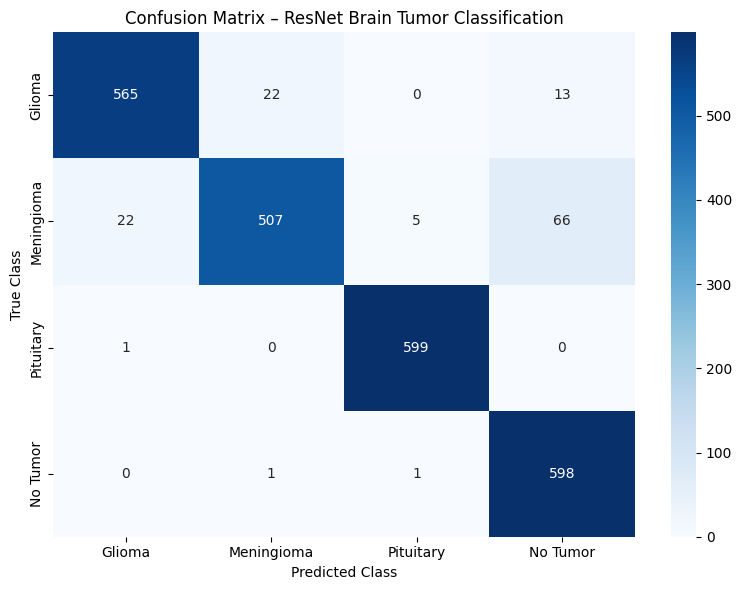

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# =========================
# Predictions
# =========================
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# =========================
# Confusion Matrix
# =========================
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix – ResNet Brain Tumor Classification")
plt.tight_layout()
plt.show()


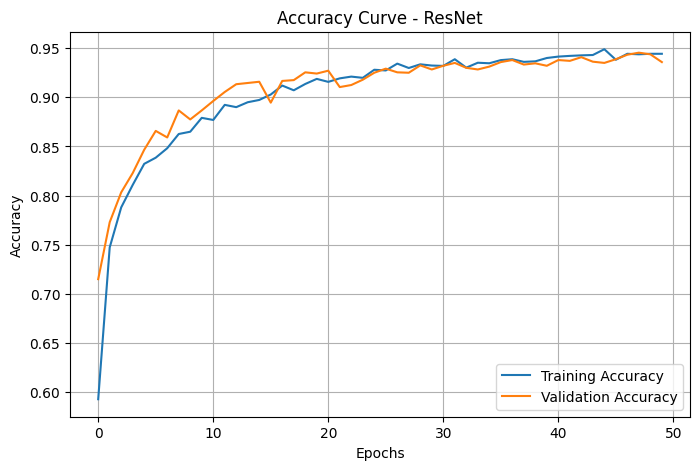

In [ ]:
import matplotlib.pyplot as plt
# Accuracy Curve
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curve - ResNet')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()



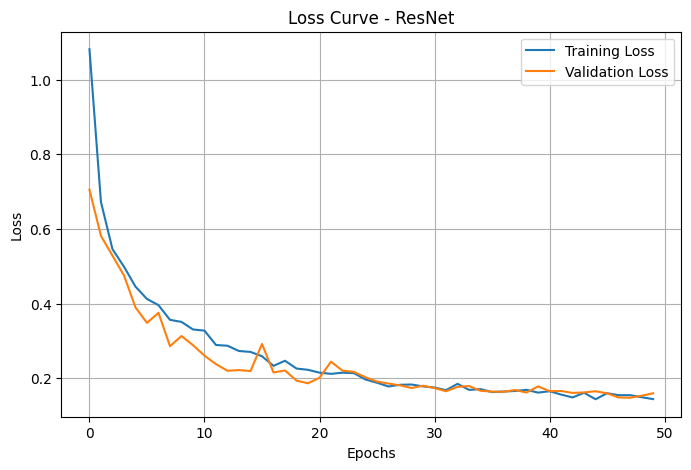

In [ ]:
# Loss Curve
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curve - ResNet')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()